# Coverage of the NLE posteriors on held-out simulated galaxies

Rows of `coverage/<mode>_<case>_<tag>.csv`, one per galaxy: star count used, log10 r_half, true and median log10 rho(150 pc), 68% half-width (dex), z and PIT of the truth. Selection mode: the same galaxies with no selection, only R < r_half, only R > r_half (a position-only selection cancels from a likelihood conditioned on R, so coverage should hold in all three). Mixed mode: v_los on all stars, v_los on half + (v_x, v_y) on the other half, all three components.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT)); sys.path.insert(0, os.path.expanduser('~/my_modules'))
os.chdir(ROOT)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
MODELS = Path(os.path.expanduser('~/scratch/projects/sbi_dsph/trained_models/nle/nle_8p_ZhaoPlumCOM_v4'))
OUT = Path(os.path.expanduser('~/scratch/projects/nle_dsph'))

In [2]:
from scipy.stats import kstest
MODE, TAG = 'selection', 'shard41'   # or 'mixed'
files = sorted((OUT / 'coverage').glob(f'{MODE}_*_{TAG}.csv'))
rows = []
for f in files:
    d = pd.read_csv(f); case = f.stem[len(MODE) + 1:-len(TAG) - 1]
    rows.append(dict(case=case, galaxies=len(d), median_halfwidth=d.halfwidth.median(), rms_z=np.sqrt((d.z**2).mean()), frac_abs_z_le_1=(d.z.abs() <= 1).mean(), mean_z=d.z.mean(), pit_ks_p=kstest(d.pit, 'uniform').pvalue))
display(pd.DataFrame(rows).round(3))

""


/tmp/ipykernel_969802/1635561331.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[0].legend(); plt.show()


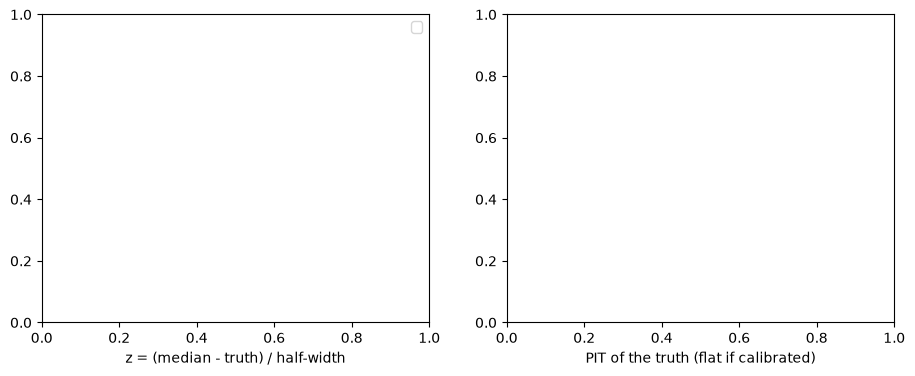

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for f in files:
    d = pd.read_csv(f); case = f.stem[len(MODE) + 1:-len(TAG) - 1]
    ax[0].hist(d.z, bins=np.linspace(-4, 4, 25), histtype='step', lw=1.6, label=case)
    ax[1].hist(d.pit, bins=np.linspace(0, 1, 11), histtype='step', lw=1.6, label=case)
ax[0].set_xlabel('z = (median - truth) / half-width'); ax[1].set_xlabel('PIT of the truth (flat if calibrated)')
ax[0].legend(); plt.show()